# Problema 5. Simulación de sesgo, varianza y selección

**Estructura**
- (a) Generación de los datos
- (b) Ajustes OLS / Ridge / Lasso y descomposición sesgo–varianza
- (c) Lasso: selección de variables y recuperación del soporte
- (d) Preguntas de interpretación

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.simulacionP5 import generar_todos, semillas, registro_semillas
from tests.experimentoP5 import (correr_experimento, ajustar_replicas,
                                 ridge_teorico, comparar_ridge_teoria, LAMBDAS)

pd.set_option("display.float_format", "{:.4g}".format)

---
## (a) Generación de los datos

- $N = 120$ filas de entrenamiento y $M = 1000$ de auditoría, $D = 20$ variables en 4 bloques de 5.
- $\Sigma_\rho$: varianza 1, correlación $\rho$ dentro de cada bloque y 0 entre bloques; $\rho \in \{0,\ 0.9\}$.
- $w^\star_1 = 3,\ w^\star_6 = -2,\ w^\star_{11} = 1.5,\ w^\star_{16} = -1$; resto en cero.
- $X$ y $X_*$ fijas en cada escenario; $R = 40$ respuestas $y^{(r)} = Xw^\star + \varepsilon^{(r)}$, con $\varepsilon^{(r)} \sim \mathcal N(0, I_N)$.
- Intercepto 0 y conocido; sin escalado.
- Semilla maestra 2026 y subsemillas con `SeedSequence.spawn`. Los dos escenarios usan los mismos $Z$, $Z_*$ y $\varepsilon^{(r)}$ (números aleatorios comunes); solo cambia $L$ en $X = ZL^\top$.

### a.1 Generación y registro de semillas

In [21]:
E = generar_todos()               # {0.0: Escenario, 0.9: Escenario}
print(registro_semillas(semillas()))

{'maestra': 2026, 'X': (0,), 'Xstar': (1,), 'eps': [(2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10), (2, 11), (2, 12), (2, 13), (2, 14), (2, 15), (2, 16), (2, 17), (2, 18), (2, 19), (2, 20), (2, 21), (2, 22), (2, 23), (2, 24), (2, 25), (2, 26), (2, 27), (2, 28), (2, 29), (2, 30), (2, 31), (2, 32), (2, 33), (2, 34), (2, 35), (2, 36), (2, 37), (2, 38), (2, 39)]}


### a.2 Verificación empírica del diseño

In [22]:
bloque = np.kron(np.eye(4), np.ones((5, 5))) - np.eye(20)   # pares dentro de un mismo bloque
fuera = 1 - np.kron(np.eye(4), np.ones((5, 5)))              # pares de bloques distintos

filas = []
for rho, esc in E.items():
    C = np.corrcoef(esc.X.T)
    filas.append({"rho": rho,
                  "corr_dentro": C[bloque == 1].mean(),
                  "corr_entre": C[fuera == 1].mean(),
                  "var_media": esc.X.var(axis=0).mean(),
                  "cond(XᵀX)": np.linalg.cond(esc.X.T @ esc.X),
                  "var(f*)": esc.f_star.var(),
                  "f*_igual_entre_rho": np.allclose(esc.f_star, E[0.0].f_star)})
pd.DataFrame(filas)

,rho,corr_dentro,corr_entre,var_media,cond(XᵀX),var(f*),f*_igual_entre_rho
0,0,-0.03402,-0.007027,0.9709,5.335,15.47,True
1,0.9,0.9001,-0.007867,0.971,151.6,15.47,True


---
## (b) Ajustes y descomposición sesgo–varianza

- OLS, Ridge y Lasso con `fit_intercept=False`, $\Lambda = \{10^{-3}, 10^{-2}, 10^{-1}, 1, 10\}$; cada regularizador activa solo su penalización.
- Convención: $F = \frac{1}{2N}\|y - Xw\|^2 + \text{pen}(w)$, así que Ridge con $\lambda$ equivale al $N\lambda$ clásico.
- $\hat B^2$, $\hat V$ y $\hat E_f$ con las fórmulas del enunciado ($1/R$ en $\hat V$).

### b.1 Ajustes en todas las réplicas

In [23]:
tabla, coefs = correr_experimento(E)
tabla

,rho,modelo,lambda,B2,V,E_f,B2+V,dif_identidad,E_nueva(E_f+s2),E_nueva_MC,no_nulos_medio,iter_max,no_convergio
0,0,OLS,NaN,0.007825,0.2023,0.2101,0.2101,5.551e-17,1.21,1.217,20,0,0
1,0,Ridge,0.001,0.007772,0.2017,0.2094,0.2094,0,1.209,1.217,20,0,0
2,0,Ridge,0.01,0.009511,0.1962,0.2057,0.2057,2.776e-17,1.206,1.213,20,0,0
3,0,Ridge,0.1,0.1821,0.1533,0.3354,0.3354,0,1.335,1.341,20,0,0
4,0,Ridge,1,3.954,0.03888,3.993,3.993,0,4.993,4.986,20,0,0
5,0,Ridge,10,12.63,0.001312,12.63,12.63,1.776e-15,13.63,13.61,20,0,0
6,0,Lasso,0.001,0.007645,0.1984,0.206,0.206,0,1.206,1.213,19.68,108,0
7,0,Lasso,0.01,0.006653,0.1671,0.1738,0.1738,2.776e-17,1.174,1.181,18.32,107,0
8,0,Lasso,0.1,0.03282,0.05065,0.08347,0.08347,1.388e-17,1.083,1.091,7.825,72,0
9,0,Lasso,1,3.052,0.02988,3.082,3.082,0,4.082,4.073,3.7,39,0


### b.2 Verificaciones: identidad, convergencia y respuesta nueva ruidosa

In [24]:
print("Máx |Ê_f − (B̂² + V̂)|        :", tabla["dif_identidad"].max())
print("Ajustes de Lasso sin converger :", int(tabla["no_convergio"].sum()))
print("Iteraciones máx. Lasso por ρ   :", tabla[tabla.modelo == "Lasso"].groupby("rho")["iter_max"].max().to_dict())
print("Máx |E_nueva_MC − (Ê_f + σ²)|  :", (tabla["E_nueva_MC"] - tabla["E_nueva(E_f+s2)"]).abs().max())

Máx |Ê_f − (B̂² + V̂)|        : 1.7763568394002505e-15
Ajustes de Lasso sin converger : 0
Iteraciones máx. Lasso por ρ   : {0.0: 108, 0.9: 2969}
Máx |E_nueva_MC − (Ê_f + σ²)|  : 0.03277823920480216


### b.3 Resumen compacto (λ = 0 corresponde a OLS)

In [25]:
resumen = (tabla.assign(**{"lambda": tabla["lambda"].fillna(0.0)})
                .pivot_table(index=["modelo", "lambda"], columns="rho",
                             values=["B2", "V", "E_f", "no_nulos_medio"]))
resumen

B2              E_f               V           \
rho                0        0.9     0      0.9      0        0.9   
modelo lambda                                                      
Lasso  0.001  0.007645 0.007045   0.206 0.1988   0.1984   0.1918   
       0.01   0.006653 0.006592  0.1738  0.133   0.1671   0.1264   
       0.1     0.03282  0.04765 0.08347 0.1074  0.05065  0.05975   
       1         3.052    3.049   3.082   3.08  0.02988  0.03156   
       10        15.49    15.49   15.49  15.49        0        0   
OLS    0      0.007825 0.007825  0.2101 0.2101   0.2023   0.2023   
Ridge  0.001  0.007772 0.007156  0.2094 0.2045   0.2017   0.1973   
       0.01   0.009511  0.02435  0.2057 0.1865   0.1962   0.1621   
       0.1      0.1821    0.445  0.3354   0.51   0.1533  0.06505   
       1         3.954    1.551   3.993  1.574  0.03888  0.02356   
       10        12.63    7.701   12.63  7.704 0.001312 0.003106   

              no_nulos_medio        
rho                      0     0.9  
modelo lambda                       
Lasso  0.001           19.68  19.6  
       0.01            18.32 15.18  
       0.1             7.825   7.8  
       1                 3.7  4.25  
       10                  0     0  
OLS    0                  20    20  
Ridge  0.001              20    20  
       0.01               20    20  
       0.1                20    20  
       1                  20    20  
       10                 20    20

### b.4 Ridge: media y covarianza empíricas frente a las teóricas

In [26]:
comp = pd.DataFrame([comparar_ridge_teoria(E[rho], lam, coefs[(rho, "Ridge", lam)])
                     for rho in E for lam in LAMBDAS])
comp

,rho,lambda,err_rel_media,err_rel_cov,B2_empirico,B2_teorico,V_empirico,V_teorico,V_teorico*(R-1)/R
0,0,0.001,0.02208,0.5887,0.007772,2.524e-05,0.2017,0.2122,0.2069
1,0,0.01,0.02201,0.5926,0.009511,0.002435,0.1962,0.2063,0.2011
2,0,0.1,0.02138,0.6228,0.1821,0.1788,0.1533,0.16,0.156
3,0,1,0.01838,0.6771,3.954,3.942,0.03888,0.03973,0.03874
4,0,10,0.01617,0.6539,12.63,12.62,0.001312,0.001323,0.00129
5,0.9,0.001,0.06481,0.5361,0.007156,0.0003219,0.1973,0.2075,0.2023
6,0.9,0.01,0.06301,0.5626,0.02435,0.02372,0.1621,0.1691,0.1649
7,0.9,0.1,0.04686,0.6278,0.445,0.4493,0.06505,0.06607,0.06441
8,0.9,1,0.01459,0.6457,1.551,1.535,0.02356,0.02363,0.02304
9,0.9,10,0.007451,0.3844,7.701,7.68,0.003106,0.003197,0.003117


Escala del error de Monte Carlo para la media: $\sqrt{\operatorname{tr}\operatorname{Cov}(\hat w)/R}$.

In [27]:
filas = []
for rho in E:
    for lam in LAMBDAS:
        W = coefs[(rho, "Ridge", lam)]
        m_t, C_t = ridge_teorico(E[rho], lam)
        filas.append({"rho": rho, "lambda": lam,
                      "‖media_emp − media_teo‖": np.linalg.norm(W.mean(0) - m_t),
                      "escala_MC": np.sqrt(np.trace(C_t) / W.shape[0])})
pd.DataFrame(filas)

,rho,lambda,‖media_emp − media_teo‖,escala_MC
0,0,0.001,0.0889,0.0726
1,0,0.01,0.08777,0.07157
2,0,0.1,0.07804,0.06302
3,0,1,0.03838,0.03142
4,0,10,0.006683,0.005735
5,0.9,0.001,0.2584,0.2035
6,0.9,0.01,0.23,0.1798
7,0.9,0.1,0.1141,0.09008
8,0.9,1,0.02287,0.01955
9,0.9,10,0.004543,0.004556


### b.5 Gráfica de la descomposición

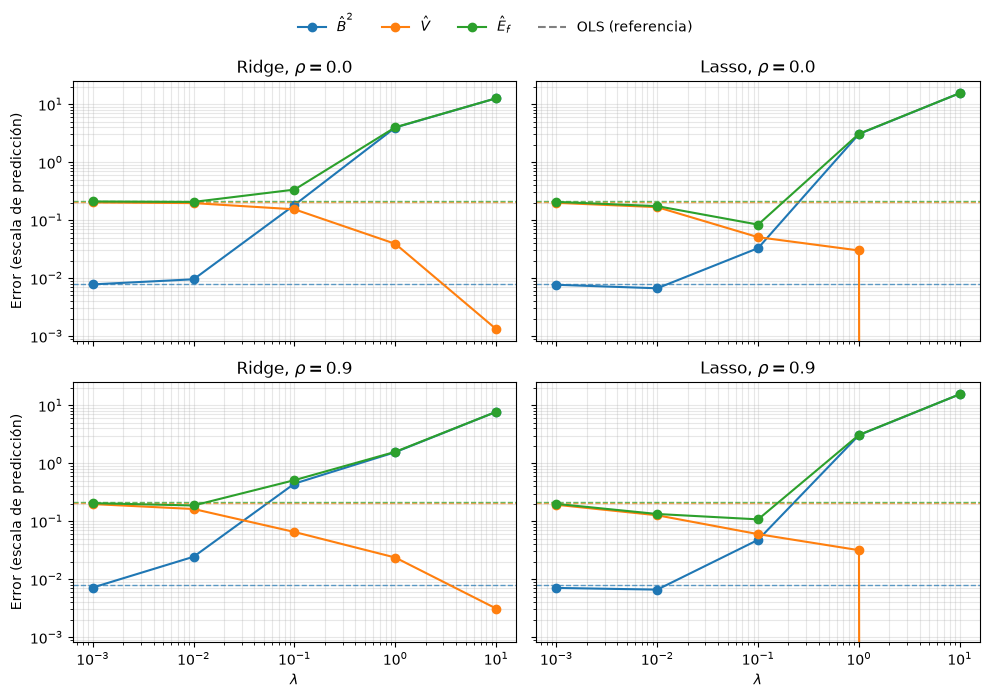

In [28]:
def graficar_descomposicion(tabla, ruta=None):
    """B̂², V̂ y Ê_f contra λ; filas = ρ, columnas = modelo. OLS como referencia horizontal."""
    rhos = sorted(tabla["rho"].unique())
    modelos = ["Ridge", "Lasso"]
    metricas = {"B2": (r"$\hat B^2$", "C0"),
                "V": (r"$\hat V$", "C1"),
                "E_f": (r"$\hat E_f$", "C2")}

    fig, axes = plt.subplots(len(rhos), len(modelos), figsize=(10, 7),
                             sharex=True, sharey=True)
    for i, rho in enumerate(rhos):
        ols = tabla[(tabla.rho == rho) & (tabla.modelo == "OLS")].iloc[0]
        for j, mod in enumerate(modelos):
            ax = axes[i, j]
            d = tabla[(tabla.rho == rho) & (tabla.modelo == mod)].sort_values("lambda")
            for col, (etiqueta, color) in metricas.items():
                ax.plot(d["lambda"], d[col], "o-", color=color, label=etiqueta)
                ax.axhline(ols[col], color=color, ls="--", lw=1, alpha=0.7)
            ax.set_xscale("log")
            ax.set_yscale("log")
            ax.set_title(rf"{mod}, $\rho={rho}$")
            ax.grid(True, which="both", alpha=0.3)
            if i == len(rhos) - 1:
                ax.set_xlabel(r"$\lambda$")
            if j == 0:
                ax.set_ylabel("Error (escala de predicción)")

    h, l = axes[0, 0].get_legend_handles_labels()
    h.append(plt.Line2D([], [], color="gray", ls="--"))
    l.append("OLS (referencia)")
    fig.legend(h, l, loc="upper center", ncol=4, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    if ruta:
        fig.savefig(ruta, dpi=200, bbox_inches="tight")
    return fig

graficar_descomposicion(tabla, ruta="descomposicion_P5.pdf")
plt.show()

---
## (c) Lasso: selección de variables

- **Tolerancia:** $|\hat w_j| > 10^{-6}$ cuenta como seleccionada (declarada en c.1).
- **Precisión** $= |\hat S \cap S^\star| / |\hat S|$ (indefinida si $\hat S = \emptyset$); **sensibilidad** $= |\hat S \cap S^\star| / 4$; promedios sobre las $R$ réplicas.
- **Bloques:** un bloque está recuperado si se selecciona al menos una de sus variables. Como cada bloque contiene una variable relevante, la precisión por bloques es trivialmente 1; se reportan la sensibilidad por bloques, la fracción de réplicas con los 4 bloques y la **sustitución** (relevante ausente, otra del bloque presente).
- **Trayectorias:** malla de 33 valores de $\lambda$ en $[10^{-3}, 10]$, recorrida de mayor a menor con arranque en caliente.

### c.1 Tolerancia

In [29]:
from src.modelos import LassoProximal
from tests.experimentoP5 import descomposicion

# Tolerancia declarada antes de ver los resultados.
# ISTA anula coeficientes exactamente con el umbral suave; lo que queda por debajo de 1e-6
# es residuo de optimización (tol = 1e-10 en el paso), seis órdenes por debajo del
# menor coeficiente verdadero (|w*_16| = 1).
TOL = 1e-6
D = 20
SOPORTE = np.array([1, 6, 11, 16]) - 1
BLOQUES = np.arange(D) // 5
ES_SOP = np.isin(np.arange(D), SOPORTE)

def seleccion(W, tol=TOL):
    return np.abs(W) > tol

### c.2 Frecuencia de selección por variable

In [30]:
frec = pd.DataFrame({(rho, lam): seleccion(coefs[(rho, "Lasso", lam)]).mean(axis=0)
                     for rho in E for lam in LAMBDAS},
                    index=pd.Index(np.arange(1, D + 1), name="variable"))
frec.columns.names = ["rho", "lambda"]
frec

rho        0                             0.9                        
lambda   0.001 0.01  0.1   1     10    0.001 0.01  0.1   1     10   
variable                                                            
1            1     1     1     1     0     1     1     1     1     0
2         0.95   0.8   0.2     0     0 0.975  0.65   0.2     0     0
3         0.95  0.85  0.25     0     0     1 0.675  0.35     0     0
4        0.975  0.95 0.175     0     0     1  0.75 0.225     0     0
5        0.975  0.85 0.325     0     0  0.95 0.675 0.275     0     0
6            1     1     1     1     0     1     1     1     1     0
7         0.95 0.925   0.2     0     0 0.975  0.65   0.1     0     0
8            1   0.9 0.175     0     0     1  0.75 0.025     0     0
9        0.975 0.925   0.1     0     0 0.975  0.65  0.25     0     0
10           1 0.975 0.275     0     0 0.975   0.7   0.4 0.025     0
11           1     1     1     1     0     1     1     1     1     0
12       0.975 0.875  0.25     0     0     1  0.85  0.25     0     0
13           1 0.975 0.325     0     0 0.975 0.725   0.4   0.3     0
14       0.975 0.925   0.3     0     0 0.975 0.725  0.25     0     0
15       0.975 0.775 0.175     0     0 0.925   0.6   0.1     0     0
16           1     1     1   0.7     0     1     1     1 0.425     0
17           1   0.9  0.25     0     0     1 0.775 0.275 0.075     0
18           1 0.925 0.325     0     0   0.9  0.65  0.15     0     0
19       0.975 0.875   0.3     0     0 0.975 0.575  0.25 0.175     0
20           1   0.9   0.2     0     0     1 0.775   0.3  0.25     0

### c.3 Precisión y sensibilidad del soporte

In [31]:
def metricas(W, tol=TOL):
    S = seleccion(W, tol)
    k = S.sum(axis=1)
    vp = S[:, ES_SOP].sum(axis=1)
    prec = np.where(k > 0, vp / np.maximum(k, 1), np.nan)
    sens = vp / ES_SOP.sum()
    exacta = (S == ES_SOP).all(axis=1)
    bloq = np.stack([S[:, BLOQUES == b].any(axis=1) for b in range(4)], axis=1)
    sustituto = np.stack([(~S[:, SOPORTE[b]]) & S[:, BLOQUES == b].any(axis=1)
                          for b in range(4)], axis=1)
    sel_por_bloque = np.stack([S[:, BLOQUES == b].sum(axis=1) for b in range(4)], axis=1)
    return {"n_sel": k.mean(),
            "precision": np.nanmean(prec) if np.isfinite(prec).any() else np.nan,
            "sensibilidad": sens.mean(),
            "soporte_exacto": exacta.mean(),
            "sens_bloques": bloq.mean(),
            "bloques_completos": bloq.all(axis=1).mean(),
            "frac_sustitucion": sustituto.mean(),
            "sel_por_bloque": sel_por_bloque.mean()}

met = pd.DataFrame([{"rho": rho, "lambda": lam, **metricas(coefs[(rho, "Lasso", lam)])}
                    for rho in E for lam in LAMBDAS])
met

,rho,lambda,n_sel,precision,sensibilidad,soporte_exacto,sens_bloques,bloques_completos,frac_sustitucion,sel_por_bloque
0,0,0.001,19.68,0.2034,1,0,1,1,0,4.919
1,0,0.01,18.32,0.219,1,0,1,1,0,4.581
2,0,0.1,7.825,0.5309,1,0,1,1,0,1.956
3,0,1,3.7,1,0.925,0.7,0.925,0.7,0,0.925
4,0,10,0,NaN,0,0,0,0,0,0
5,0.9,0.001,19.6,0.2044,1,0,1,1,0,4.9
6,0.9,0.01,15.18,0.266,1,0,1,1,0,3.794
7,0.9,0.1,7.8,0.5316,1,0,1,1,0,1.95
8,0.9,1,4.25,0.8283,0.8562,0.2,0.9375,0.75,0.08125,1.062
9,0.9,10,0,NaN,0,0,0,0,0,0


### c.4 Recuperación por bloques

In [32]:
# Sustitución por bloque: el relevante no se selecciona pero otra variable del bloque sí
for rho in E:
    for lam in LAMBDAS:
        S = np.abs(coefs[(rho, 'Lasso', lam)]) > TOL
        for b in range(4):
            idx = np.where(BLOQUES == b)[0]
            casos = (~S[:, SOPORTE[b]]) & S[:, idx].any(axis=1)
            if casos.any():
                W = coefs[(rho, 'Lasso', lam)][casos][:, idx[1:]]
                print(f"rho={rho} λ={lam:.3g} bloque {b+1}: {casos.sum()} réplicas, "
                      f"suma media de los sustitutos = {W.sum(axis=1).mean():.3f}")

rho=0.9 λ=1 bloque 4: 13 réplicas, suma media de los sustitutos = -0.090


### c.5 Trayectorias de coeficientes y error predictivo

In [33]:
LAM_FINA = np.logspace(1, -3, 33)

def camino_lasso(esc, lams=LAM_FINA, tol=1e-10, max_iter=200_000):
    R = esc.Y.shape[1]
    Wc = np.zeros((len(lams), R, D))
    for r in range(R):
        m = LassoProximal(lambda1=lams[0], fit_intercept=False, tol=tol,
                          max_iter=max_iter, warm_start=True)
        for i, lam in enumerate(lams):
            m.lambda1 = lam
            m.fit(esc.X, esc.Y[:, r])
            assert m.motivo_ == "convergencia"
            Wc[i, r] = m.w_
    return Wc

caminos = {rho: camino_lasso(esc) for rho, esc in E.items()}

filas = []
for rho, esc in E.items():
    for i, lam in enumerate(LAM_FINA):
        W = caminos[rho][i]
        B2, V, Ef = descomposicion(W, esc)
        filas.append({"rho": rho, "lambda": lam, "B2": B2, "V": V, "E_f": Ef, **metricas(W)})
camino_df = pd.DataFrame(filas)
camino_df

,rho,lambda,B2,V,E_f,n_sel,precision,sensibilidad,soporte_exacto,sens_bloques,bloques_completos,frac_sustitucion,sel_por_bloque
0,0,10,15.49,0,15.49,0,NaN,0,0,0,0,0,0
1,0,7.499,15.49,0,15.49,0,NaN,0,0,0,0,0,0
2,0,5.623,15.49,0,15.49,0,NaN,0,0,0,0,0,0
3,0,4.217,15.49,0,15.49,0,NaN,0,0,0,0,0,0
4,0,3.162,15.48,4.081e-05,15.48,0.1,1,0.025,0,0.025,0,0,0.025
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,0.9,0.003162,0.006007,0.1714,0.1774,18.6,0.2157,1,0,1,1,0,4.65
62,0.9,0.002371,0.006293,0.1785,0.1848,18.88,0.2125,1,0,1,1,0,4.719
63,0.9,0.001778,0.006578,0.184,0.1906,19.2,0.2087,1,0,1,1,0,4.8
64,0.9,0.001334,0.00683,0.1884,0.1952,19.43,0.2063,1,0,1,1,0,4.856


In [34]:
# Chequeo: el camino con arranque en caliente reproduce los ajustes de (b) en Λ
for rho in E:
    for lam in LAMBDAS:
        i = np.argmin(np.abs(LAM_FINA - lam))
        print(rho, lam, f"{np.abs(caminos[rho][i] - coefs[(rho, 'Lasso', lam)]).max():.1e}")

0.0 0.001 2.4e-10
0.0 0.01 2.4e-10
0.0 0.1 1.9e-10
0.0 1.0 1.7e-11
0.0 10.0 0.0e+00
0.9 0.001 2.7e-09
0.9 0.01 2.8e-09
0.9 0.1 2.0e-09
0.9 1.0 2.6e-10
0.9 10.0 0.0e+00


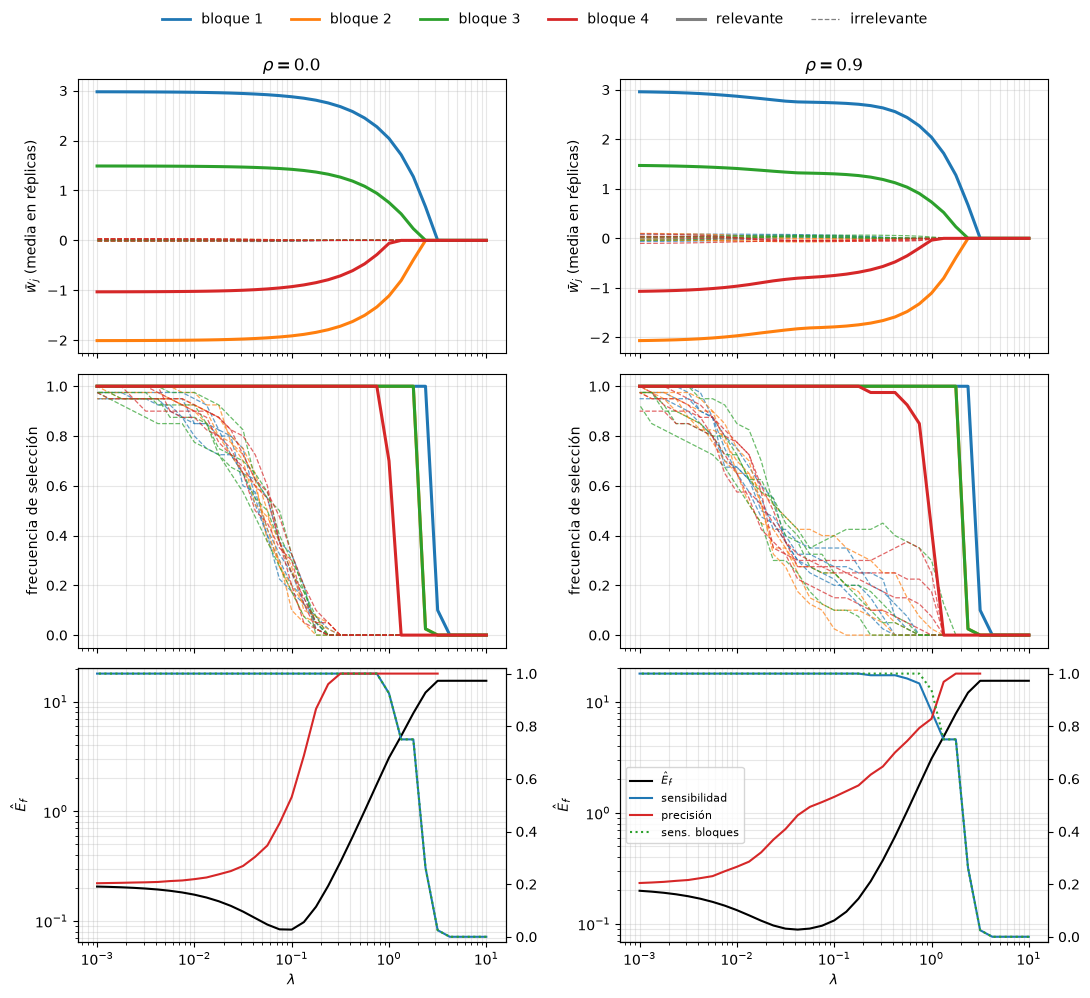

In [35]:
def graficar_caminos(caminos, camino_df, ruta=None):
    rhos = sorted(caminos)
    fig, axes = plt.subplots(3, len(rhos), figsize=(11, 10), sharex=True)
    colores = {0: "C0", 1: "C1", 2: "C2", 3: "C3"}
    for j, rho in enumerate(rhos):
        Wm = caminos[rho].mean(axis=1)                       # (n_lam, D)
        F = (np.abs(caminos[rho]) > TOL).mean(axis=1)        # (n_lam, D)
        d = camino_df[camino_df.rho == rho]
        for v in range(D):
            b = BLOQUES[v]
            estilo = dict(color=colores[b], lw=2.2 if ES_SOP[v] else 0.9,
                          ls="-" if ES_SOP[v] else "--", alpha=1 if ES_SOP[v] else 0.7)
            axes[0, j].plot(LAM_FINA, Wm[:, v], **estilo)
            axes[1, j].plot(LAM_FINA, F[:, v], **estilo)
        axes[0, j].set_title(rf"$\rho={rho}$")
        axes[0, j].set_ylabel(r"$\bar w_j$ (media en réplicas)")
        axes[1, j].set_ylabel("frecuencia de selección")
        ax = axes[2, j]
        ax.plot(d["lambda"], d["E_f"], "k-", label=r"$\hat E_f$")
        ax.set_yscale("log")
        ax.set_ylabel(r"$\hat E_f$")
        ax2 = ax.twinx()
        ax2.plot(d["lambda"], d["sensibilidad"], "C0-", label="sensibilidad")
        ax2.plot(d["lambda"], d["precision"], "C3-", label="precisión")
        ax2.plot(d["lambda"], d["sens_bloques"], "C2:", label="sens. bloques")
        ax2.set_ylim(-0.02, 1.02)
        ax.set_xlabel(r"$\lambda$")
        if j == len(rhos) - 1:
            h1, l1 = ax.get_legend_handles_labels()
            h2, l2 = ax2.get_legend_handles_labels()
            ax2.legend(h1 + h2, l1 + l2, loc="center left", fontsize=8)
        for a in axes[:, j]:
            a.set_xscale("log")
            a.grid(True, which="both", alpha=0.3)
    leyenda = [plt.Line2D([], [], color=colores[b], lw=2) for b in range(4)]
    leyenda += [plt.Line2D([], [], color="gray", lw=2.2), plt.Line2D([], [], color="gray", lw=0.9, ls="--")]
    fig.legend(leyenda, [f"bloque {b+1}" for b in range(4)] + ["relevante", "irrelevante"],
               loc="upper center", ncol=6, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    if ruta:
        fig.savefig(ruta, dpi=150, bbox_inches="tight")
    return fig

graficar_caminos(caminos, camino_df, ruta="caminos_lasso_P5.png")
plt.show()

---
## (d) Preguntas de interpretación

Cada respuesta se apoya en la evidencia de (b) y (c) recalculada en la celda de código que la precede.

### d.1 Sesgo y varianza simultáneos

In [36]:
# Sesgo teórico de Ridge frente a B̂² empírico y al término de Monte Carlo V̂/R
R = E[0.0].Y.shape[1]
d1 = comp[["rho", "lambda", "B2_teorico", "B2_empirico", "V_empirico"]].copy()
d1["V/R"] = d1["V_empirico"] / R
ols = tabla[tabla.modelo == "OLS"].set_index("rho")
print("OLS:", {rho: (round(ols.loc[rho, "B2"], 4), round(ols.loc[rho, "V"] / R, 4)) for rho in E}, "(B̂², V̂/R)")
d1

OLS: {0.0: (np.float64(0.0078), np.float64(0.0051)), 0.9: (np.float64(0.0078), np.float64(0.0051))} (B̂², V̂/R)


,rho,lambda,B2_teorico,B2_empirico,V_empirico,V/R
0,0,0.001,2.524e-05,0.007772,0.2017,0.005042
1,0,0.01,0.002435,0.009511,0.1962,0.004904
2,0,0.1,0.1788,0.1821,0.1533,0.003833
3,0,1,3.942,3.954,0.03888,0.0009719
4,0,10,12.62,12.63,0.001312,3.281e-05
5,0.9,0.001,0.0003219,0.007156,0.1973,0.004933
6,0.9,0.01,0.02372,0.02435,0.1621,0.004053
7,0.9,0.1,0.4493,0.445,0.06505,0.001626
8,0.9,1,1.535,1.551,0.02356,0.0005889
9,0.9,10,7.68,7.701,0.003106,7.765e-05


**Respuesta.** No. Al aumentar $\lambda$ la varianza baja y el sesgo sube.

- Con $\lambda$ pequeño, $\hat B^2$ y $\hat V$ bajan a la vez respecto a OLS (por ejemplo, Lasso con $\rho = 0$ y $\lambda = 10^{-2}$: $\hat B^2$ pasa de 0.0078 a 0.0067 y $\hat V$ de 0.202 a 0.167). Es un artefacto de Monte Carlo: $\mathbb E[\hat B^2] \approx B^2 + V/R$.
- OLS es insesgado ($B^2 = 0$), así que su $\hat B^2 = 0.0078$ es solo ese término, del orden de $\hat V/R \approx 0.005$. Al bajar $V$, también baja el término, y $\hat B^2$ parece mejorar.
- El sesgo exacto de Ridge crece de forma monótona con $\lambda$ (con $\rho = 0$: $2.5\cdot10^{-5}$, 0.0024, 0.18, 3.9 y 12.6). Partiendo de un estimador insesgado, el sesgo verdadero solo puede aumentar.
- La regularización sí reduce el **error total**: Lasso con $\rho = 0$ baja $\hat E_f$ de 0.210 a 0.084, porque la caída de la varianza compensa la subida del sesgo.

### d.2 Predicción frente a recuperación del soporte

In [37]:
filas = []
for rho in E:
    d = camino_df[camino_df.rho == rho]
    mejor = d.loc[d["E_f"].idxmin()]
    exacto = d[d["soporte_exacto"] == d["soporte_exacto"].max()]
    filas.append({"rho": rho,
                  "λ_min_Ef": mejor["lambda"], "Ef_min": mejor["E_f"],
                  "precision_en_min": mejor["precision"], "n_sel_en_min": mejor["n_sel"],
                  "soporte_exacto_en_min": mejor["soporte_exacto"],
                  "max_soporte_exacto": d["soporte_exacto"].max(),
                  "λ_con_max_exacto": list(exacto["lambda"].round(3)),
                  "Ef_con_max_exacto": list(exacto["E_f"].round(3))})
pd.DataFrame(filas)

,rho,λ_min_Ef,Ef_min,precision_en_min,n_sel_en_min,soporte_exacto_en_min,max_soporte_exacto,λ_con_max_exacto,Ef_con_max_exacto
0,0,0.1,0.08347,0.5309,7.825,0,1,"[0.75, 0.562, 0.422, 0.316]","[1.771, 1.011, 0.584, 0.344]"
1,0.9,0.04217,0.08883,0.4618,9,0,0.275,[0.75],[1.792]


**Respuesta.** No, en ninguna de las dos direcciones.

| $\rho$ | $\lambda$ con mínimo $\hat E_f$ | Precisión ahí | Soporte exacto ahí | $\hat E_f$ cuando el soporte es exacto |
|---|---|---|---|---|
| 0 | ≈ 0.1 ($\hat E_f = 0.084$) | 0.53 | 0 % | 0.34 a 1.77 ($\lambda \in [0.32, 0.75]$, 100 % de réplicas) |
| 0.9 | ≈ 0.04 ($\hat E_f = 0.089$) | 0.46 | 0 % | máximo 27.5 % de réplicas exactas, con $\hat E_f = 1.79$ |

**Mecanismo.**
- El umbral suave encoge cada coeficiente seleccionado en una cantidad del orden de $\lambda$. Para eliminar las irrelevantes hace falta un $\lambda$ grande, y ese mismo $\lambda$ encoge a las relevantes y dispara el sesgo.
- Las irrelevantes que sobreviven con $\lambda \approx 0.1$ tienen coeficientes pequeños y aportan poca varianza.
- Predecir bien tolera variables de más; recuperar el soporte exacto se paga con sesgo.

### d.3 Variables sustitutas

In [38]:
# Condición de irrepresentabilidad: |Σ_{j,S} Σ_{S,S}^{-1} sign(w*_S)| para cada irrelevante j
for rho, esc in E.items():
    Sig = esc.Sigma
    S, Sc = SOPORTE, np.setdiff1d(np.arange(D), SOPORTE)
    v = np.abs(Sig[np.ix_(Sc, S)] @ np.linalg.solve(Sig[np.ix_(S, S)], np.sign(esc.w_star[S])))
    print(f"rho={rho}: máx |Σ_jS Σ_SS^-1 sign(w*_S)| = {v.max():.2f}  (margen η = {1 - v.max():.2f})")

# Brecha poblacional entre la relevante y una irrelevante del mismo bloque en Cov(x, y)
print("brecha (1-ρ)|w*_b| con ρ=0.9:", dict(zip(["b1", "b2", "b3", "b4"], np.round(0.1 * np.abs(E[0.9].w_star[SOPORTE]), 2))))

# Sustitución a lo largo del camino fino
filas = []
for rho in E:
    for i, lam in enumerate(LAM_FINA):
        S_ = np.abs(caminos[rho][i]) > TOL
        for b in range(4):
            idx = np.where(BLOQUES == b)[0]
            casos = (~S_[:, SOPORTE[b]]) & S_[:, idx].any(axis=1)
            if casos.any():
                filas.append({"rho": rho, "lambda": lam, "bloque": b + 1, "réplicas": int(casos.sum()),
                              "suma_sustitutos": caminos[rho][i][casos][:, idx[1:]].sum(axis=1).mean()})
pd.DataFrame(filas)

rho=0.0: máx |Σ_jS Σ_SS^-1 sign(w*_S)| = 0.00  (margen η = 1.00)
rho=0.9: máx |Σ_jS Σ_SS^-1 sign(w*_S)| = 0.90  (margen η = 0.10)
brecha (1-ρ)|w*_b| con ρ=0.9: {'b1': np.float64(0.3), 'b2': np.float64(0.2), 'b3': np.float64(0.15), 'b4': np.float64(0.1)}


,rho,lambda,bloque,réplicas,suma_sustitutos
0,0.9,1,4,13,-0.09002
1,0.9,0.7499,4,6,-0.2986
2,0.9,0.5623,4,3,-0.532
3,0.9,0.4217,4,1,-0.5649
4,0.9,0.3162,4,1,-0.6691
5,0.9,0.2371,4,1,-0.7469


**Respuesta.** Cuando se dan tres condiciones a la vez. En los datos, la sustitución aparece solo con $\rho = 0.9$, solo en el bloque 4 y solo con $\lambda \geq 0.24$; es frecuente únicamente con $\lambda$ grande (1 réplica con $\lambda \le 0.42$, 6 con $\lambda = 0.75$ y 13 de 40 con $\lambda = 1$).

1. **Alta correlación con la variable relevante.** Con $\rho = 0$ nunca hay sustitución: una variable independiente de la relevante no contiene su señal.
2. **Señal débil.** La covarianza poblacional con $y$ vale $\rho\, w^\star_b$ para una irrelevante del bloque y $w^\star_b$ para la relevante. La brecha es $(1-\rho)|w^\star_b|$: 0.1 en el bloque 4 ($|w^\star| = 1$) frente a 0.3 en el bloque 1 ($|w^\star| = 3$). Con $N = 120$ datos ruidosos, una brecha de 0.1 se puede invertir.
3. **$\lambda$ grande.** Lasso conserva un solo representante por bloque. Si el ruido hace ganar a una variable vecina, la relevante queda fuera.

Los sustitutos conservan el signo de $w^\star_{16} = -1$ (suma media negativa): el bloque sigue aportando la señal en la misma dirección, a través de otra variable.

**Formal.** La condición de irrepresentabilidad exige $|\Sigma_{S^c S}\Sigma_{SS}^{-1}\operatorname{sign}(w^\star_S)| \le 1-\eta$ con $\eta > 0$. Aquí $\Sigma_{SS} = I$ (una relevante por bloque) y la expresión vale $\rho = 0.9$: la condición se cumple, pero con margen $\eta = 0.1$. Un margen tan estrecho hace que la recuperación falle en muestras finitas cuando la señal es débil. Con $\rho = 0$ la expresión vale 0 y el margen es máximo.